# omnicontext_gen_lora_r8_step1000 — the 400-row benchmark with the checkpoint-1000 adapter
Derived from `lora_arm_step1000_r8` by swapping the data source only: `DATASET`, and the cell that restores references and loads rows. Adapter path, pipeline build, sampler, resolution, negative prompt, seed and the resumable engine are the domain notebook's, unchanged, so this run and the domain run differ in the benchmark and nothing else.

Reads `omnicontext/manifest.jsonl` and `omnicontext/images/` built by `build_omnicontext`, at the pinned dataset revision. Rows are the frozen manifest order; output is `gen/omnicontext/lora_r8_step1000/{i:05d}.png`.

The pipeline build grafts the converted adapter with `transformer.load_lora_adapter`. `inference.py` uses `pipeline.load_lora_weights`, which fails against current diffusers — OmniGen2's `lora_state_dict` iterates the return value of `_fetch_state_dict`, now a `(state_dict, metadata)` tuple.

Cost: 400 rows at roughly 20 s/img, near 2.3 h. Reference tokens run lower here than on the domain split because OmniContext references are mostly 3:2 rather than square.


## 1. Repo

In [1]:
import os, subprocess, sys
REPO = "/content/OmniGen2"
if not os.path.isdir(REPO):
    subprocess.run(["git","clone","https://github.com/VectorSpaceLab/OmniGen2.git",REPO], check=True)
    subprocess.run([sys.executable,"-m","pip","install","-q","-r","requirements.txt"], cwd=REPO, check=True)
    subprocess.run([sys.executable,"-m","pip","install","-q","-U","huggingface_hub[hf_xet]>=0.30.0,<1.0"], check=True)
    print("installed.")
else:
    print("OmniGen2 already present.")

# peft's LoRA injection walks dispatch_torchao, which raises rather than returning False when torchao
# predates 0.16 (Colab ships 0.10). torchao is unused by this bf16 path; removing it lets injection
# proceed. Same fix the converter and training notebooks use. Guarded, so it is a no-op once gone.
_ao = subprocess.run([sys.executable, "-c",
                      "from peft.import_utils import is_torchao_available; is_torchao_available()"],
                     capture_output=True, text=True)
if _ao.returncode != 0:
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=True)
    print("torchao removed")

sys.path.insert(0, REPO)
os.chdir(REPO)

installed.
torchao removed


## 2. Drive, run config, adapter path

In [3]:
from google.colab import drive, userdata
import os
drive.mount("/content/drive")
os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")

DRIVE   = "/content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data"
DATASET = "omnicontext"   # the 400-row public benchmark, 8 subtasks x 50
RANK    = 8               # 4 | 8 | 16 — the adapter under test
STEP    = 1000            # selected on GPT-4.1 PF/SC over the val slice, argmax across all three ranks
RUN     = f"lora_r{RANK}_step{STEP}"

EXP      = f"{DRIVE}/lora/experiments"
# the main run's checkpoint, not lora_r8_early's: the two are the same weights (val loss agrees to
# 1e-5 at every matched step) but the selection rule was applied to the main run
LORA_DIR = f"{EXP}/lora_r{RANK}/checkpoint-{STEP}/transformer_lora"
LORA     = f"{LORA_DIR}/pytorch_lora_weights.safetensors"
assert os.path.exists(LORA), f"adapter missing, run lora_convert_steps first: {LORA}"

GEN = f"{DRIVE}/gen/{DATASET}/{RUN}"
os.makedirs(GEN, exist_ok=True)
# guard: GEN is derived from RUN alone, so a mismatched STEP would silently write into another
# checkpoint's directory, where skip-if-exists would then score the wrong images
assert f"checkpoint-{STEP}" in LORA_DIR and f"step{STEP}" in GEN, "adapter step and output directory disagree"

n_have = len([f for f in os.listdir(GEN) if f.endswith(".png")])
print(f"data    : {DRIVE}")
print(f"adapter : {LORA}")
print(f"output  : {GEN}")
print(f"already generated: {n_have}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
data    : /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data
adapter : /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data/lora/experiments/lora_r8/checkpoint-1000/transformer_lora/pytorch_lora_weights.safetensors
output  : /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data/gen/omnicontext/lora_r8_step1000
already generated: 0


## 3. Images, split files

In [4]:
import subprocess, json
OC       = f"{DRIVE}/omnicontext"
TAR      = f"{OC}/images.tar"
LOCALTAR = "/content/oc_images.tar"
LOCAL    = "/content/oc"
IMGS     = f"{LOCAL}/images"

rows     = [json.loads(l) for l in open(f"{OC}/manifest.jsonl", encoding="utf-8")]
REVISION = open(f"{OC}/revision.txt").read().strip()
EXPECTED = sum(len(r["input_images"]) for r in rows)

def n_files(d): return sum(len(f) for _,_,f in os.walk(d)) if os.path.isdir(d) else 0

if os.path.exists(TAR):
    subprocess.run(["cp", TAR, LOCALTAR], check=True)
else:
    # tar exits non-zero writing into the Drive FUSE mount; build locally, copy the one file up
    _r = subprocess.run(["tar", "-cf", LOCALTAR, "-C", OC, "images"], capture_output=True, text=True)
    assert os.path.exists(LOCALTAR), _r.stderr[-800:]
    subprocess.run(["cp", LOCALTAR, TAR], check=True)
if n_files(IMGS) < EXPECTED:
    os.makedirs(LOCAL, exist_ok=True)
    subprocess.run(["tar", "-xf", LOCALTAR, "-C", LOCAL], check=True)

assert n_files(IMGS) == EXPECTED, (n_files(IMGS), EXPECTED)
missing = [p for r in rows for p in r["input_images"] if not os.path.exists(os.path.join(IMGS, p))]
assert not missing, f"{len(missing)} reference images missing, first: {missing[:3]}"
print(f"{DATASET}: {len(rows)} rows, all reference images present | revision {REVISION[:12]}")


omnicontext: 400 rows, all reference images present | revision 0f6aabbe8d34


## 4. Model and adapter

In [5]:
import torch
from accelerate import Accelerator
from omnigen2.pipelines.omnigen2.pipeline_omnigen2 import OmniGen2Pipeline
from omnigen2.models.transformers.transformer_omnigen2 import OmniGen2Transformer2DModel

MODEL = "OmniGen2/OmniGen2"
accelerator = Accelerator(mixed_precision="bf16")
dtype = torch.bfloat16

# same construction as inference.py load_pipeline (base pipeline, base transformer), except that
# the adapter is grafted with transformer.load_lora_adapter: inference.py's pipeline.load_lora_weights
# fails against current diffusers, since OmniGen2's lora_state_dict iterates the return value of
# _fetch_state_dict, now a (state_dict, metadata) tuple
pipe = OmniGen2Pipeline.from_pretrained(MODEL, torch_dtype=dtype, trust_remote_code=True)
pipe.transformer = OmniGen2Transformer2DModel.from_pretrained(MODEL, subfolder="transformer", torch_dtype=dtype)
pipe.transformer.load_lora_adapter(LORA_DIR, weight_name="pytorch_lora_weights.safetensors", prefix="transformer")
pipe = pipe.to(accelerator.device)
print(f"pipeline ready on {accelerator.device} with adapter r{RANK} loaded")

Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/content/OmniGen2/omnigen2/models/attention_processor.py:33: UserWarning: Cannot import flash_attn, install flash_attn to use Flash2Varlen attention for better performance
  warnings.warn("Cannot import flash_attn, install flash_attn to use Flash2Varlen attention for better performance")
/content/OmniGen2/omnigen2/models/transformers/block_lumina2.py:37: UserWarning: Cannot import flash_attn, install flash_attn to use fused SwiGLU for better performance
  warnings.warn("Cannot import flash_attn, install flash_attn to use fused SwiGLU for better performance")


model_index.json:   0%|          | 0.00/462 [00:00<?, ?B/s]

Fetching 24 files:   0%|          | 0/24 [00:00<?, ?it/s]

mllm/model-00004-of-00004.safetensors:   0%|          | 0.00/180M [00:00<?, ?B/s]

mllm/model-00001-of-00004.safetensors:   0%|          | 0.00/4.97G [00:00<?, ?B/s]

...

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
Expected types for transformer: (<class 'omnigen2.models.transformers.transformer_omnigen2.OmniGen2Transformer2DModel'>,), got <class 'diffusers_modules.local.transformer_omnigen2.OmniGen2Transformer2DModel'>.


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

pipeline ready on cuda with adapter r8 loaded


## 5. Engine and run config

In [6]:
from PIL import Image, ImageOps
import torch

# shipped default from inference.py and omnicontext/inference.py; quality filter, not a domain negative
NEG = ("(((deformed))), blurry, over saturation, bad anatomy, disfigured, poorly drawn face, mutation, mutated, "
       "(extra_limb), (ugly), (poorly drawn hands), fused fingers, messy drawing, broken legs censor, censored, censor_bar")

def load_inputs(paths, max_side=512):   # refs downscaled; output size fixed at 512 via align_res=False
    out = []
    for p in paths:
        im = ImageOps.exif_transpose(Image.open(p).convert("RGB"))
        w, h = im.size
        s = max_side / max(w, h)
        if s < 1: w, h = int(w*s), int(h*s)
        w, h = max(16, (w//16)*16), max(16, (h//16)*16)
        out.append(im.resize((w, h), Image.LANCZOS))
    return out

def generate(instruction, input_images=None, negative=NEG, seed=0, steps=50, text_g=5.0, image_g=2.0, size=512):
    gen = torch.Generator(device=accelerator.device).manual_seed(seed)
    res = pipe(prompt=instruction, input_images=input_images,
               width=size, height=size, num_inference_steps=steps, max_sequence_length=1024,
               text_guidance_scale=text_g, image_guidance_scale=image_g, cfg_range=(0.0, 1.0),
               negative_prompt=negative, num_images_per_prompt=1, generator=gen, output_type="pil",
               align_res=False)
    return res.images[0]

# no prompt lever in this arm: the adapter is the treatment, instruction and negative are the baseline
cfg = dict(instruction=lambda r: r["instruction"], negative=NEG)
_probe = {"instruction": "<probe>", "input_images": []}
print(f"run '{RUN}'")
print(f"  instruction : {'unchanged' if cfg['instruction'](_probe) == '<probe>' else 'transformed'}")
print(f"  negative    : {'shipped default' if cfg['negative'] == NEG else 'custom'}")
print(f"  sampler     : 50 steps, text_g=5.0, image_g=2.0, cfg_range=(0,1), seed 0, 512x512  (fixed across all conditions)")

run 'lora_r8_step1000'
  instruction : unchanged
  negative    : shipped default
  sampler     : 50 steps, text_g=5.0, image_g=2.0, cfg_range=(0,1), seed 0, 512x512  (fixed across all conditions)


## 6. Smoke — 3 rows

  0%|          | 0/50 [00:00<?, ?it/s]

row 0: 1 ref(s), output (512, 512), 31.2s


  0%|          | 0/50 [00:00<?, ?it/s]

row 1: 1 ref(s), output (512, 512), 22.4s


  0%|          | 0/50 [00:00<?, ?it/s]

row 2: 1 ref(s), output (512, 512), 21.0s


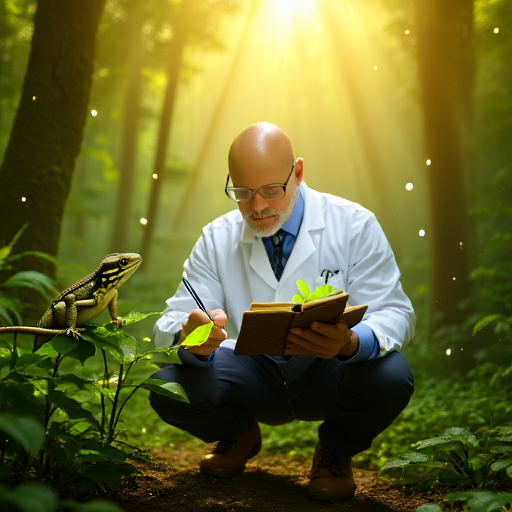

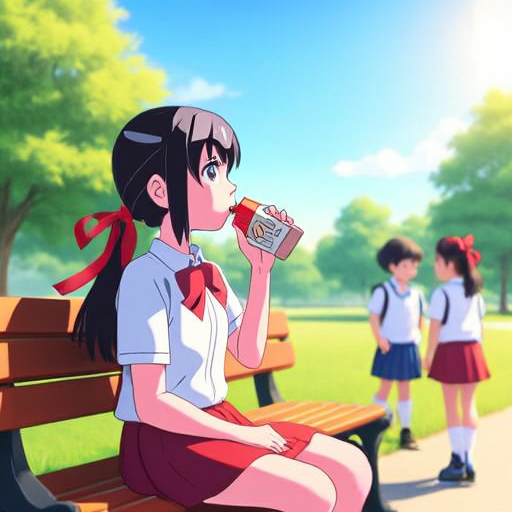

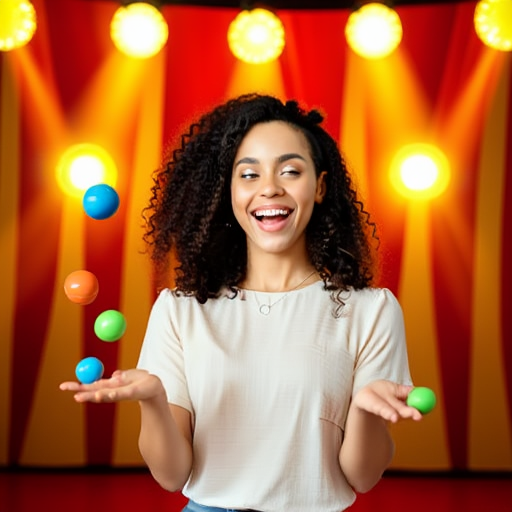

In [7]:
import time
for i in range(3):
    r = rows[i]
    refs = load_inputs([os.path.join(IMGS, p) for p in r["input_images"]])
    t = time.time()
    img = generate(cfg["instruction"](r), input_images=refs, negative=cfg["negative"], seed=0)
    print(f"row {i}: {len(refs)} ref(s), output {img.size}, {time.time()-t:.1f}s")
    assert img.size == (512, 512), f"expected 512x512, got {img.size}"
    img.save(f"/content/smoke_{i}.png")

from IPython.display import display
for i in range(3):
    display(Image.open(f"/content/smoke_{i}.png"))

## 7. Full pass (resumable)

In [8]:
import time
done, t0 = 0, time.time()
for i, r in enumerate(rows):
    out = f"{GEN}/{i:05d}.png"
    if os.path.exists(out):
        continue
    refs = load_inputs([os.path.join(IMGS, p) for p in r["input_images"]])
    img = generate(cfg["instruction"](r), input_images=refs, negative=cfg["negative"], seed=0)
    assert img.size == (512, 512), (i, img.size)
    img.save(out)
    done += 1
    if done % 10 == 0:
        print(f"generated {done} (at row {i+1}/{len(rows)}), {(time.time()-t0)/done:.1f}s/img")

total = len([f for f in os.listdir(GEN) if f.endswith(".png")])
print(f"\n{DATASET}/{RUN}: {total}/{len(rows)} images in {GEN}")
assert total == len(rows), "incomplete"

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

...

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

generated 400 (at row 400/400), 25.2s/img

omnicontext/lora_r8_step1000: 400/400 images in /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data/gen/omnicontext/lora_r8_step1000


## 8. Manifest

In [9]:
# manifest: provenance for the images in GEN. Written only when this session generated some,
# so a skip-through or resumed run cannot stamp the wrong GPU onto images made earlier.
if not done:
    print(f"no images generated this session; {GEN}/manifest.json left as-is")
else:
    import json, time, subprocess, torch
    man = {
        "dataset": DATASET, "run": RUN, "step": STEP, "dataset_revision": REVISION,
        "n_images": len([f for f in os.listdir(GEN) if f.endswith(".png")]),
        "gpu": torch.cuda.get_device_name(0),
        "driver": subprocess.run("nvidia-smi --query-gpu=driver_version --format=csv,noheader",
                                 shell=True, capture_output=True, text=True).stdout.strip(),
        "torch": torch.__version__, "cuda": torch.version.cuda, "model": MODEL,
        "sampler": dict(steps=50, text_guidance_scale=5.0, image_guidance_scale=2.0,
                        cfg_range=[0.0, 1.0], max_sequence_length=1024, seed=0,
                        size=512, align_res=False),
        "negative_prompt": cfg["negative"],
        "instruction_row0": cfg["instruction"](rows[0]),
        "bit_reproducible": False,
        "written": time.strftime("%Y-%m-%d %H:%M:%S"),
    }
    with open(f"{GEN}/manifest.json", "w") as f:
        json.dump(man, f, indent=2)
    print("manifest written:", f"{GEN}/manifest.json")

manifest written: /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data/gen/omnicontext/lora_r8_step1000/manifest.json
